In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.manifold import TSNE

In [2]:
chronos_path = Path("../artifacts/embeddings/chronos_wesad_256_512_null_ecg")
chronos_df = pd.read_csv(chronos_path / "annotations.csv")
X_chronos_embeddings = np.stack([np.load(chronos_path / filename) for filename in chronos_df["file"]])
y_chronos = chronos_df["label"].to_numpy()

moment_path = Path("../artifacts/embeddings/moment_wesad_256_512_null_ecg")
moment_df = pd.read_csv(moment_path / "annotations.csv")
X_moment_embeddings = np.stack([np.load(moment_path / filename) for filename in moment_df["file"]])
y_moment = moment_df["label"].to_numpy()

normwear_path = Path("../artifacts/embeddings/normwear_wesad_256_512_null_ecg")
normwear_df = pd.read_csv(normwear_path / "annotations.csv")
X_normwear_embeddings = np.stack([np.load(normwear_path / filename) for filename in normwear_df["file"]])
y_normwear = normwear_df["label"].to_numpy()

tsjepa_path = Path("../artifacts/embeddings/tsjepa_wesad_256_512_null_ecg")
tsjepa_df = pd.read_csv(tsjepa_path / "annotations.csv")
X_tsjepa_embeddings = np.stack([np.load(tsjepa_path / filename) for filename in tsjepa_df["file"]])
y_tsjepa = tsjepa_df["label"].to_numpy()

lejepa_path = Path("../artifacts/embeddings/lejepa_wesad_256_512_null_ecg")
lejepa_df = pd.read_csv(lejepa_path / "annotations.csv")
X_lejepa_embeddings = np.stack([np.load(lejepa_path / filename) for filename in lejepa_df["file"]])
y_lejepa = lejepa_df["label"].to_numpy()


In [3]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=1)
X_chronos_reduced = tsne.fit_transform(X_chronos_embeddings)
X_moment_reduced = tsne.fit_transform(X_moment_embeddings)
X_normwear_reduced = tsne.fit_transform(X_normwear_embeddings)
X_tsjepa_reduced = tsne.fit_transform(X_tsjepa_embeddings)
X_lejepa_reduced = tsne.fit_transform(X_lejepa_embeddings)

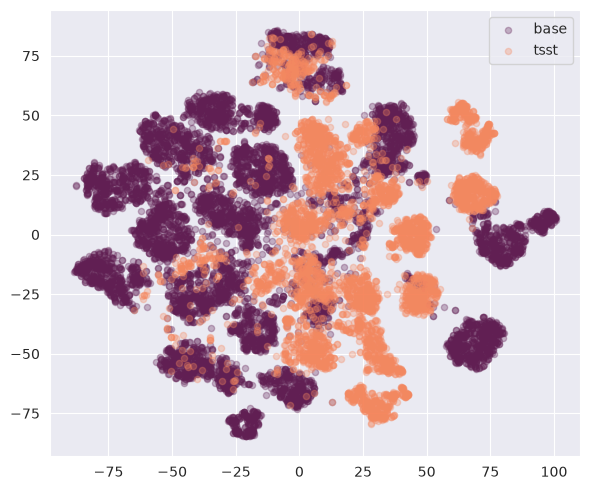

In [4]:
with sns.axes_style("darkgrid"):
    rocket = sns.color_palette("rocket", as_cmap=True)

    plt.figure(figsize=(6, 5))
    plt.scatter(X_chronos_reduced[y_chronos == 0, 0], X_chronos_reduced[y_chronos == 0, 1], color=rocket(0.25), alpha=0.3, s=20, label="base")
    plt.scatter(X_chronos_reduced[y_chronos == 1, 0], X_chronos_reduced[y_chronos == 1, 1], color=rocket(0.75), alpha=0.3, s=20, label="tsst")
    plt.legend()
    plt.tight_layout()
    plt.show()


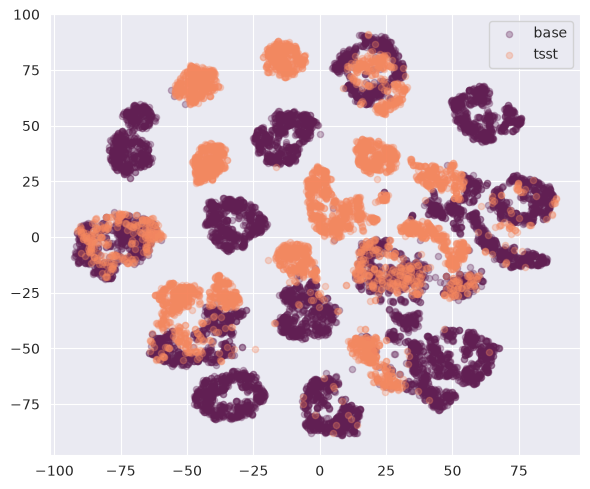

In [5]:
with sns.axes_style("darkgrid"):
    plt.figure(figsize=(6, 5))
    plt.scatter(X_moment_reduced[y_moment == 0, 0], X_moment_reduced[y_moment == 0, 1], color=rocket(0.25), alpha=0.3, s=20, label="base")
    plt.scatter(X_moment_reduced[y_moment == 1, 0], X_moment_reduced[y_moment == 1, 1], color=rocket(0.75), alpha=0.3, s=20, label="tsst")
    plt.legend()
    plt.tight_layout()
    plt.show()


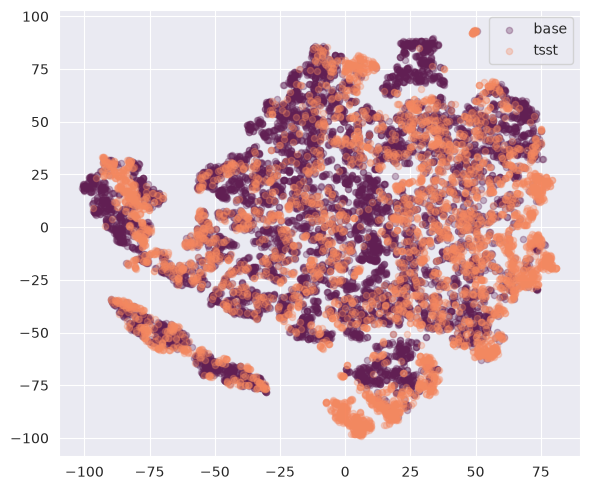

In [6]:
with sns.axes_style("darkgrid"):
    plt.figure(figsize=(6, 5))
    plt.scatter(X_normwear_reduced[y_normwear == 0, 0], X_normwear_reduced[y_normwear == 0, 1], color=rocket(0.25), alpha=0.3, s=20, label="base")
    plt.scatter(X_normwear_reduced[y_normwear == 1, 0], X_normwear_reduced[y_normwear == 1, 1], color=rocket(0.75), alpha=0.3, s=20, label="tsst")
    plt.legend()
    plt.tight_layout()
    plt.show()


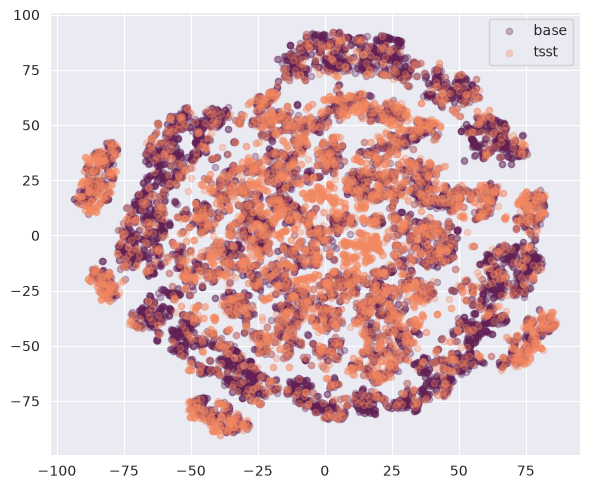

In [7]:
with sns.axes_style("darkgrid"):
    plt.figure(figsize=(6, 5))
    plt.scatter(X_tsjepa_reduced[y_tsjepa == 0, 0], X_tsjepa_reduced[y_tsjepa == 0, 1], color=rocket(0.25), alpha=0.3, s=20, label="base")
    plt.scatter(X_tsjepa_reduced[y_tsjepa == 1, 0], X_tsjepa_reduced[y_tsjepa == 1, 1], color=rocket(0.75), alpha=0.3, s=20, label="tsst")
    plt.legend()
    plt.tight_layout()
    plt.show()


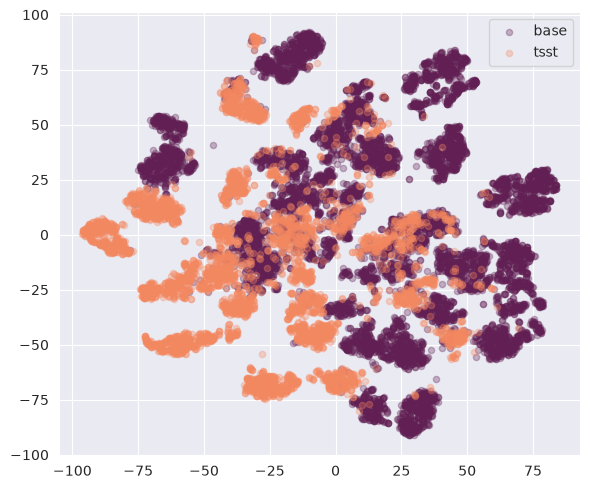

In [8]:
with sns.axes_style("darkgrid"):
    plt.figure(figsize=(6, 5))
    plt.scatter(X_lejepa_reduced[y_lejepa == 0, 0], X_lejepa_reduced[y_lejepa == 0, 1], color=rocket(0.25), alpha=0.3, s=20, label="base")
    plt.scatter(X_lejepa_reduced[y_lejepa == 1, 0], X_lejepa_reduced[y_lejepa == 1, 1], color=rocket(0.75), alpha=0.3, s=20, label="tsst")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [9]:
inference_path = Path("../inference")

with open(inference_path / "linear_probing_chronos_wesad_256_512_null_ecg/results.json") as f:
    chronos_results = json.load(f)
with open(inference_path / "linear_probing_moment_wesad_256_512_null_ecg/results.json") as f:
    moment_results = json.load(f)
with open(inference_path / "linear_probing_normwear_wesad_256_512_null_ecg/results.json") as f:
    normwear_results = json.load(f)
with open(inference_path / "linear_probing_tsjepa_wesad_256_512_null_ecg/results.json") as f:
    tsjepa_results = json.load(f)
with open(inference_path / "linear_probing_lejepa_wesad_256_512_null_ecg/results.json") as f:
    lejepa_results = json.load(f)

chronos_metrics = pd.json_normalize(chronos_results).assign(model="CHRONOS")
moment_metrics = pd.json_normalize(moment_results).assign(model="MOMENT")
normwear_metrics = pd.json_normalize(normwear_results).assign(model="NORMWEAR")
tsjepa_metrics = pd.json_normalize(tsjepa_results).assign(model="TS-JEPA")
lejepa_metrics = pd.json_normalize(lejepa_results).assign(model="LeJEPA")

results_df = pd.concat([chronos_metrics, moment_metrics, normwear_metrics, tsjepa_metrics, lejepa_metrics], ignore_index=True)
metrics_df = results_df.melt(id_vars=["model", "group"], value_vars=["group_results.balanced_accuracy", "group_results.f1_macro", "group_results.accuracy", "group_results.mcc", "group_results.auroc"], var_name="metric", value_name="score").dropna(subset=["score"])

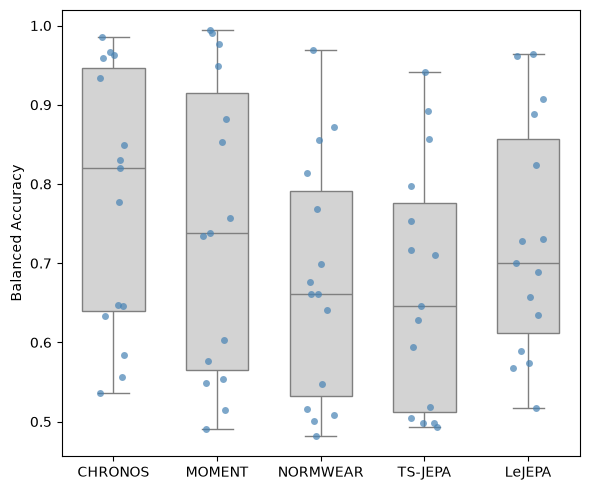

In [10]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=metrics_df[metrics_df["metric"] == "group_results.balanced_accuracy"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6)
sns.stripplot(data=metrics_df[metrics_df["metric"] == "group_results.balanced_accuracy"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15)
plt.xlabel("")
plt.ylabel("Balanced Accuracy")
plt.tight_layout()
plt.show()


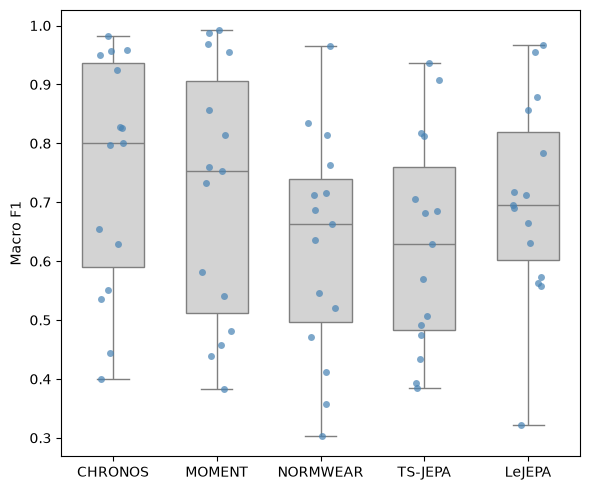

In [11]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=metrics_df[metrics_df["metric"] == "group_results.f1_macro"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6)
sns.stripplot(data=metrics_df[metrics_df["metric"] == "group_results.f1_macro"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15)
plt.xlabel("")
plt.ylabel("Macro F1")
plt.tight_layout()
plt.show()


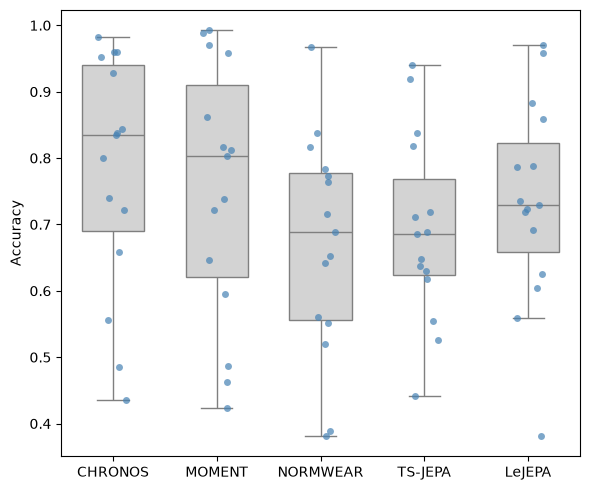

In [12]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=metrics_df[metrics_df["metric"] == "group_results.accuracy"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6)
sns.stripplot(data=metrics_df[metrics_df["metric"] == "group_results.accuracy"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15)
plt.xlabel("")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()


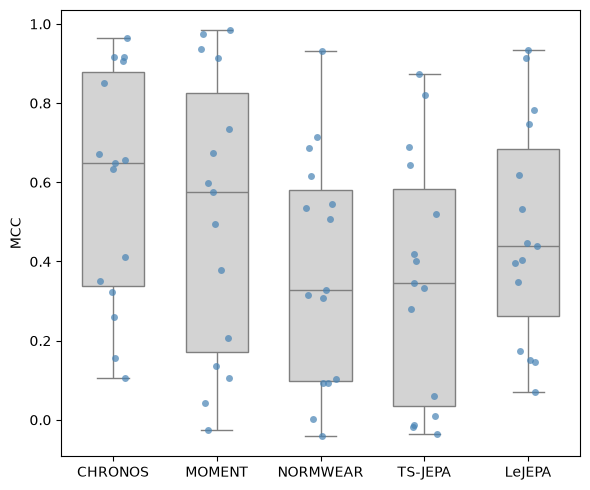

In [13]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=metrics_df[metrics_df["metric"] == "group_results.mcc"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6)
sns.stripplot(data=metrics_df[metrics_df["metric"] == "group_results.mcc"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15)
plt.xlabel("")
plt.ylabel("MCC")
plt.tight_layout()
plt.show()


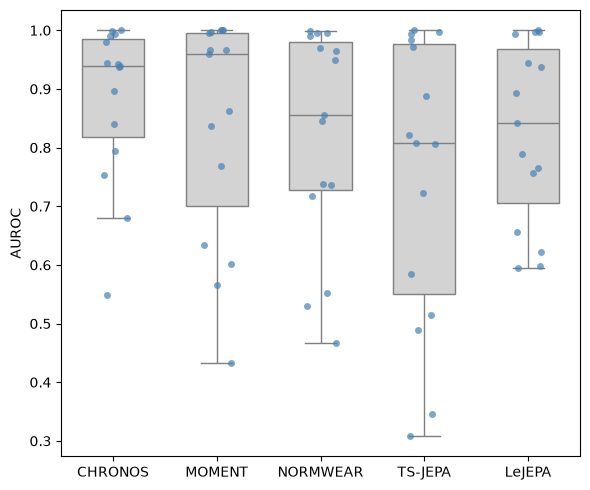

In [14]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=metrics_df[metrics_df["metric"] == "group_results.auroc"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6)
sns.stripplot(data=metrics_df[metrics_df["metric"] == "group_results.auroc"], x="model", y="score", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15)
plt.xlabel("")
plt.ylabel("AUROC")
plt.tight_layout()
plt.show()


In [ ]:
chronos_scarcity_path = inference_path / "data_scarcity_chronos_wesad_256_512_Training data per class (%)null_ecg"
chronos_scarcity_results = pd.concat([
    pd.json_normalize(json.loads((chronos_scarcity_path / "lf_0.01.json").read_text())),
    pd.json_normalize(json.loads((chronos_scarcity_path / "lf_0.05.json").read_text())),
    pd.json_normalize(json.loads((chronos_scarcity_path / "lf_0.1.json").read_text())),
    pd.json_normalize(json.loads((chronos_scarcity_path / "lf_0.25.json").read_text())),
    pd.json_normalize(json.loads((chronos_scarcity_path / "lf_0.5.json").read_text())),
    pd.json_normalize(json.loads((chronos_scarcity_path / "lf_1.0.json").read_text())),
], ignore_index=True).assign(model="CHRONOS")

moment_scarcity_path = inference_path / "data_scarcity_moment_wesad_256_512_null_ecg"
moment_scarcity_results = pd.concat([
    pd.json_normalize(json.loads((moment_scarcity_path / "lf_0.01.json").read_text())),
    pd.json_normalize(json.loads((moment_scarcity_path / "lf_0.05.json").read_text())),
    pd.json_normalize(json.loads((moment_scarcity_path / "lf_0.1.json").read_text())),
    pd.json_normalize(json.loads((moment_scarcity_path / "lf_0.25.json").read_text())),
    pd.json_normalize(json.loads((moment_scarcity_path / "lf_0.5.json").read_text())),
    pd.json_normalize(json.loads((moment_scarcity_path / "lf_1.0.json").read_text())),
], ignore_index=True).assign(model="MOMENT")

normwear_scarcity_path = inference_path / "data_scarcity_normwear_wesad_256_512_null_ecg"
normwear_scarcity_results = pd.concat([
    pd.json_normalize(json.loads((normwear_scarcity_path / "lf_0.01.json").read_text())),
    pd.json_normalize(json.loads((normwear_scarcity_path / "lf_0.05.json").read_text())),
    pd.json_normalize(json.loads((normwear_scarcity_path / "lf_0.1.json").read_text())),
    pd.json_normalize(json.loads((normwear_scarcity_path / "lf_0.25.json").read_text())),
    pd.json_normalize(json.loads((normwear_scarcity_path / "lf_0.5.json").read_text())),
    pd.json_normalize(json.loads((normwear_scarcity_path / "lf_1.0.json").read_text())),
], ignore_index=True).assign(model="NORMWEAR")

tsjepa_scarcity_path = inference_path / "data_scarcity_tsjepa_wesad_256_512_null_ecg"
tsjepa_scarcity_results = pd.concat([
    pd.json_normalize(json.loads((tsjepa_scarcity_path / "lf_0.01.json").read_text())),
    pd.json_normalize(json.loads((tsjepa_scarcity_path / "lf_0.05.json").read_text())),
    pd.json_normalize(json.loads((tsjepa_scarcity_path / "lf_0.1.json").read_text())),
    pd.json_normalize(json.loads((tsjepa_scarcity_path / "lf_0.25.json").read_text())),
    pd.json_normalize(json.loads((tsjepa_scarcity_path / "lf_0.5.json").read_text())),
    pd.json_normalize(json.loads((tsjepa_scarcity_path / "lf_1.0.json").read_text())),
], ignore_index=True).assign(model="TS-JEPA")

lejepa_scarcity_path = inference_path / "data_scarcity_lejepa_wesad_256_512_null_ecg"
lejepa_scarcity_results = pd.concat([
    pd.json_normalize(json.loads((lejepa_scarcity_path / "lf_0.01.json").read_text())),
    pd.json_normalize(json.loads((lejepa_scarcity_path / "lf_0.05.json").read_text())),
    pd.json_normalize(json.loads((lejepa_scarcity_path / "lf_0.1.json").read_text())),
    pd.json_normalize(json.loads((lejepa_scarcity_path / "lf_0.25.json").read_text())),
    pd.json_normalize(json.loads((lejepa_scarcity_path / "lf_0.5.json").read_text())),
    pd.json_normalize(json.loads((lejepa_scarcity_path / "lf_1.0.json").read_text())),
], ignore_index=True).assign(model="LeJEPA")

scarcity_df = pd.concat([chronos_scarcity_results, moment_scarcity_results, normwear_scarcity_results, tsjepa_scarcity_results, lejepa_scarcity_results], ignore_index=True)
scarcity_df["label_percentage"] = scarcity_df["label_fraction"] * 100


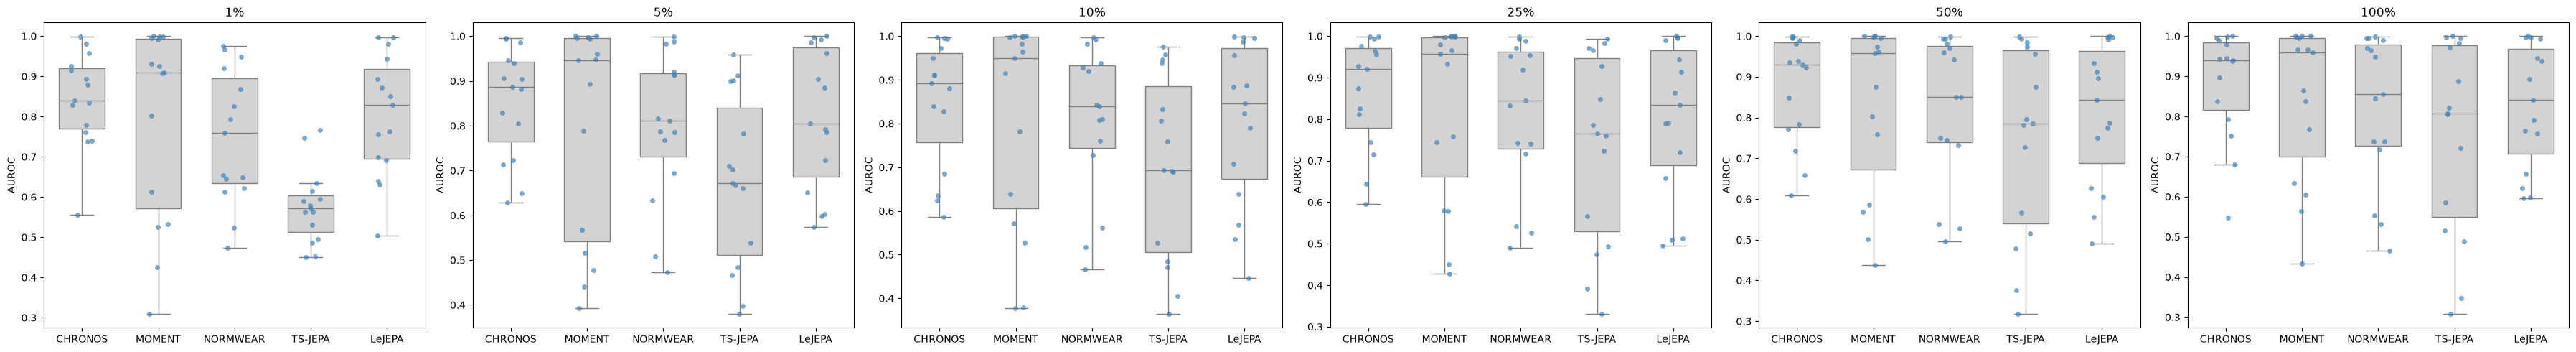

In [16]:
fig, axes = plt.subplots(1, 6, figsize=(36, 5))
sns.boxplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.01], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[0])
sns.stripplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.01], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[0])
axes[0].set_title("1%")
axes[0].set_xlabel("")
axes[0].set_ylabel("AUROC")
sns.boxplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.05], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[1])
sns.stripplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.05], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[1])
axes[1].set_title("5%")
axes[1].set_xlabel("")
axes[1].set_ylabel("AUROC")
sns.boxplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.1], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[2])
sns.stripplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.1], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[2])
axes[2].set_title("10%")
axes[2].set_xlabel("")
axes[2].set_ylabel("AUROC")
sns.boxplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.25], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[3])
sns.stripplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.25], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[3])
axes[3].set_title("25%")
axes[3].set_xlabel("")
axes[3].set_ylabel("AUROC")
sns.boxplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.5], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[4])
sns.stripplot(data=scarcity_df[scarcity_df["label_fraction"] == 0.5], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[4])
axes[4].set_title("50%")
axes[4].set_xlabel("")
axes[4].set_ylabel("AUROC")
sns.boxplot(data=scarcity_df[scarcity_df["label_fraction"] == 1.0], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[5])
sns.stripplot(data=scarcity_df[scarcity_df["label_fraction"] == 1.0], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[5])
axes[5].set_title("100%")
axes[5].set_xlabel("")
axes[5].set_ylabel("AUROC")
plt.tight_layout()
plt.show()

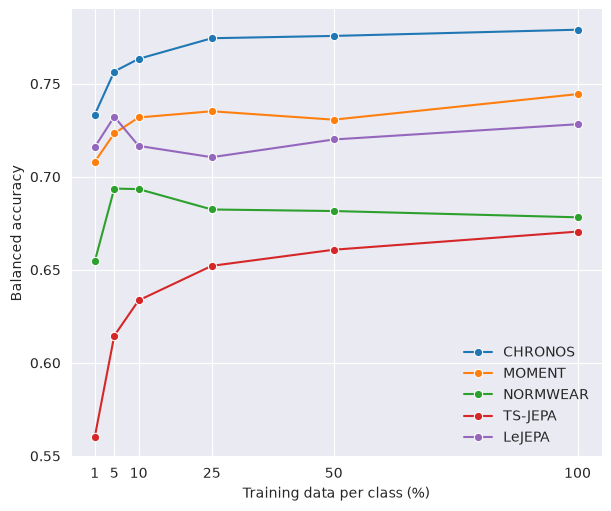

In [34]:
fractions = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0]
scarcity_df["label_fraction"] = scarcity_df["label_fraction"].astype(float)

with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
    sns.lineplot(data=scarcity_df, x="label_fraction", y="group_results.balanced_accuracy", hue="model", hue_order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], palette="tab10", marker="o", linewidth=1.5, estimator="mean", errorbar=None, ax=ax)
    ax.set_xticks(fractions, labels=["1", "5", "10", "25", "50", "100"])
    ax.set(xlabel="Training data per class (%)", ylabel="Balanced accuracy")
    ax.legend(title=None, loc="best", frameon=False)
    sns.despine(ax=ax)

plt.show()

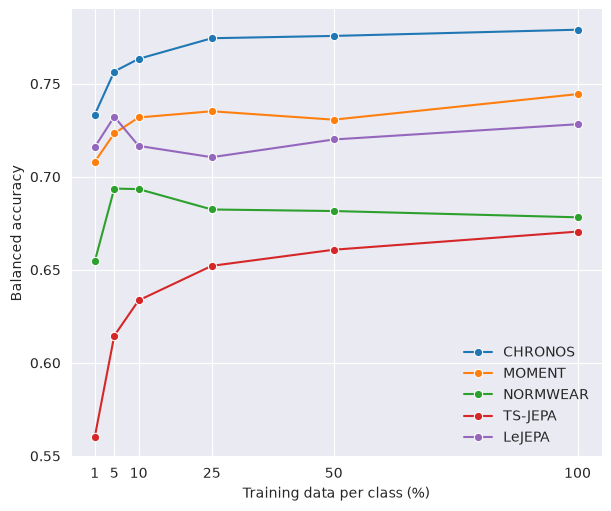

In [35]:
scarcity_df["label_fraction"] = scarcity_df["label_fraction"].astype(float)

with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
    sns.lineplot(data=scarcity_df, x="label_fraction", y="group_results.balanced_accuracy", hue="model", hue_order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], palette="tab10", marker="o", linewidth=1.5, estimator="mean", errorbar=None, ax=ax)
    ax.set_xticks(fractions, labels=["1", "5", "10", "25", "50", "100"])
    ax.set(xlabel="Training data per class (%)", ylabel="Balanced accuracy")
    ax.legend(title=None, loc="best", frameon=False)
    sns.despine(ax=ax)

plt.show()

In [ ]:
chronos_noise_path = inference_path / "noise_stress_chronos_wesad_256_512_null_ecg"
chronos_noise_results = pd.concat([labels=["1%", "5%", "10%", "25%", "50%", "100%"]
    pd.json_normalize(json.loads((chronos_noise_path / "snr_0.json").read_text())).assign(noise_level="0 dB"),
    pd.json_normalize(json.loads((chronos_noise_path / "snr_10.json").read_text())).assign(noise_level="10 dB"),
    pd.json_normalize(json.loads((chronos_noise_path / "snr_20.json").read_text())).assign(noise_level="20 dB"),
    pd.json_normalize(json.loads((chronos_noise_path / "clean.json").read_text())).assign(noise_level="Clean"),
], ignore_index=True).assign(model="CHRONOS")

moment_noise_path = inference_path / "noise_stress_moment_wesad_256_512_null_ecg"
moment_noise_results = pd.concat([
    pd.json_normalize(json.loads((moment_noise_path / "snr_0.json").read_text())).assign(noise_level="0 dB"),
    pd.json_normalize(json.loads((moment_noise_path / "snr_10.json").read_text())).assign(noise_level="10 dB"),
    pd.json_normalize(json.loads((moment_noise_path / "snr_20.json").read_text())).assign(noise_level="20 dB"),
    pd.json_normalize(json.loads((moment_noise_path / "clean.json").read_text())).assign(noise_level="Clean"),
], ignore_index=True).assign(model="MOMENT")

normwear_noise_path = inference_path / "noise_stress_normwear_wesad_256_512_null_ecg"
normwear_noise_results = pd.concat([
    pd.json_normalize(json.loads((normwear_noise_path / "snr_0.json").read_text())).assign(noise_level="0 dB"),
    pd.json_normalize(json.loads((normwear_noise_path / "snr_10.json").read_text())).assign(noise_level="10 dB"),
    pd.json_normalize(json.loads((normwear_noise_path / "snr_20.json").read_text())).assign(noise_level="20 dB"),
    pd.json_normalize(json.loads((normwear_noise_path / "clean.json").read_text())).assign(noise_level="Clean"),
], ignore_index=True).assign(model="NORMWEAR")

tsjepa_noise_path = inference_path / "noise_stress_tsjepa_wesad_256_512_null_ecg"
tsjepa_noise_results = pd.concat([
    pd.json_normalize(json.loads((tsjepa_noise_path / "snr_0.json").read_text())).assign(noise_level="0 dB"),
    pd.json_normalize(json.loads((tsjepa_noise_path / "snr_10.json").read_text())).assign(noise_level="10 dB"),
    pd.json_normalize(json.loads((tsjepa_noise_path / "snr_20.json").read_text())).assign(noise_level="20 dB"),
    pd.json_normalize(json.loads((tsjepa_noise_path / "clean.json").read_text())).assign(noise_level="Clean"),
], ignore_index=True).assign(model="TS-JEPA")

lejepa_noise_path = inference_path / "noise_stress_lejepa_wesad_256_512_null_ecg"
lejepa_noise_results = pd.concat([
    pd.json_normalize(json.loads((lejepa_noise_path / "snr_0.json").read_text())).assign(noise_level="0 dB"),
    pd.json_normalize(json.loads((lejepa_noise_path / "snr_10.json").read_text())).assign(noise_level="10 dB"),
    pd.json_normalize(json.loads((lejepa_noise_path / "snr_20.json").read_text())).assign(noise_level="20 dB"),
    pd.json_normalize(json.loads((lejepa_noise_path / "clean.json").read_text())).assign(noise_level="Clean"),
], ignore_index=True).assign(model="LeJEPA")

noise_df = pd.concat([chronos_noise_results, moment_noise_results, normwear_noise_results, tsjepa_noise_results, lejepa_noise_results], ignore_index=True)
noise_df["noise_level"] = pd.Categorical(noise_df["noise_level"], categories=["0 dB", "10 dB", "20 dB", "Clean"], ordered=True)

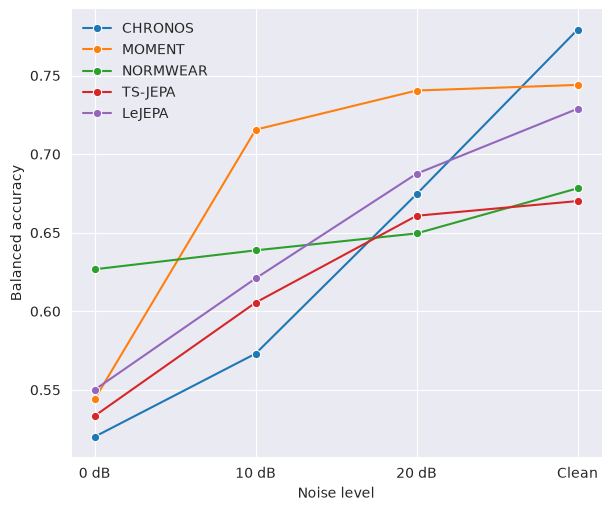

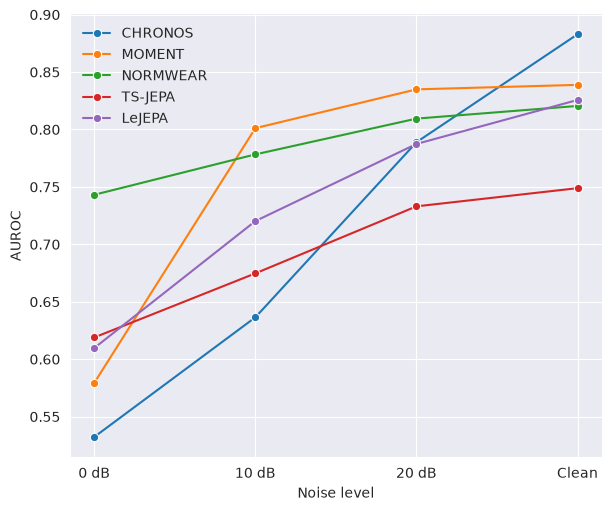

In [20]:
with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
    sns.lineplot(data=noise_df, x="noise_level", y="group_results.balanced_accuracy", hue="model", hue_order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], palette="tab10", marker="o", linewidth=1.5, estimator="mean", errorbar=None, ax=ax)
    ax.set(xlabel="Noise level", ylabel="Balanced accuracy")
    ax.legend(title=None, loc="best", frameon=False)
    sns.despine(ax=ax)
    plt.show()

    fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
    sns.lineplot(data=noise_df, x="noise_level", y="group_results.auroc", hue="model", hue_order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], palette="tab10", marker="o", linewidth=1.5, estimator="mean", errorbar=None, ax=ax)
    ax.set(xlabel="Noise level", ylabel="AUROC")
    ax.legend(title=None, loc="best", frameon=False)
    sns.despine(ax=ax)
    plt.show()

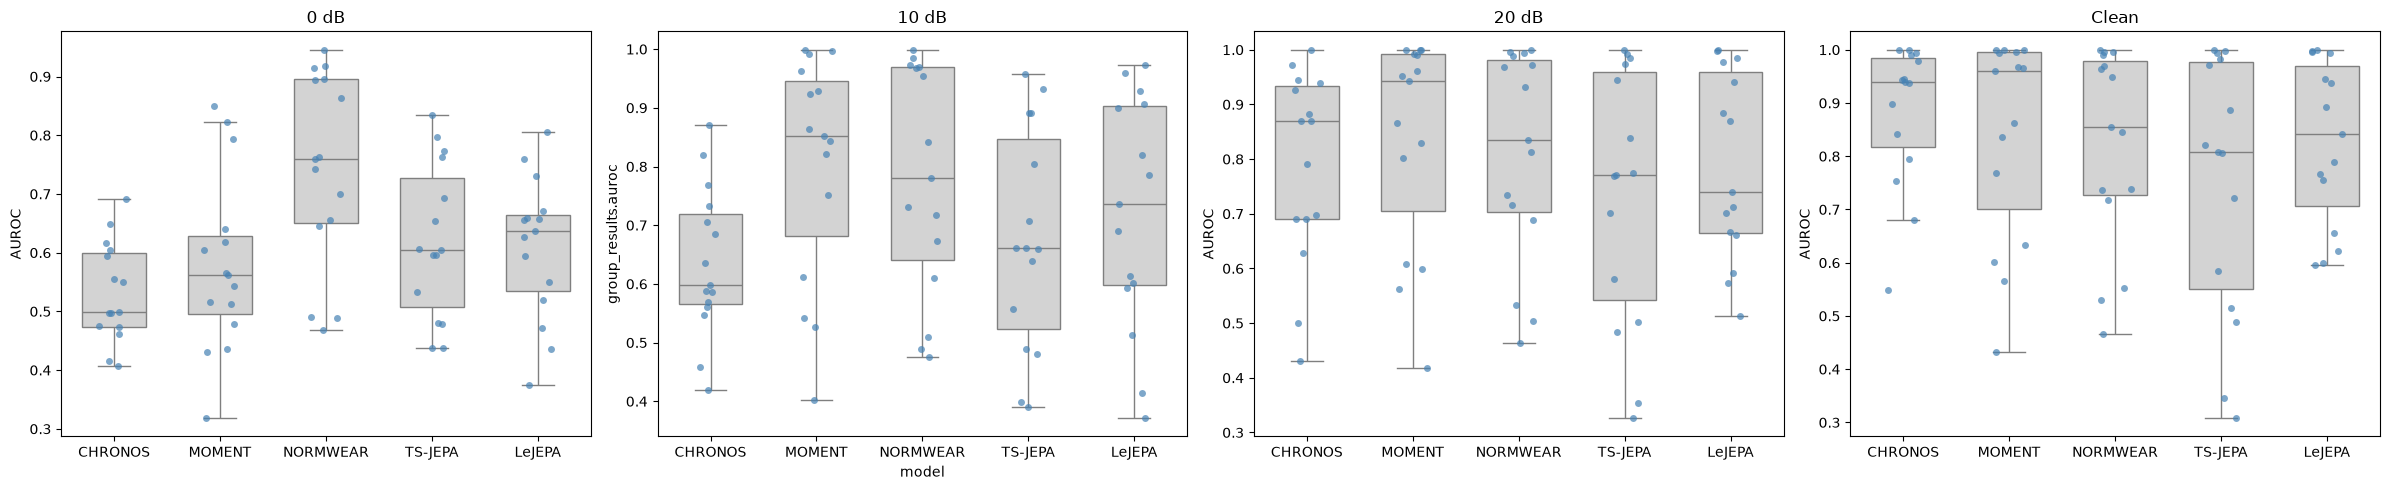

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
sns.boxplot(data=noise_df[noise_df["noise_level"] == "0 dB"], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[0])
sns.stripplot(data=noise_df[noise_df["noise_level"] == "0 dB"], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[0])
axes[0].set_title("0 dB")
axes[0].set_xlabel("")
axes[0].set_ylabel("AUROC")
sns.boxplot(data=noise_df[noise_df["noise_level"] == "10 dB"], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[1])
sns.stripplot(data=noise_df[noise_df["noise_level"] == "10 dB"], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[1])
axes[1].set_title("10 dB")
sns.boxplot(data=noise_df[noise_df["noise_level"] == "20 dB"], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[2])
sns.stripplot(data=noise_df[noise_df["noise_level"] == "20 dB"], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[2])
axes[2].set_title("20 dB")
axes[2].set_xlabel("")
axes[2].set_ylabel("AUROC")
sns.boxplot(data=noise_df[noise_df["noise_level"] == "Clean"], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="lightgray", showfliers=False, width=0.6, ax=axes[3])
sns.stripplot(data=noise_df[noise_df["noise_level"] == "Clean"], x="model", y="group_results.auroc", order=["CHRONOS", "MOMENT", "NORMWEAR", "TS-JEPA", "LeJEPA"], color="steelblue", alpha=0.7, jitter=0.15, ax=axes[3])
axes[3].set_title("Clean")
axes[3].set_xlabel("")
axes[3].set_ylabel("AUROC")
plt.tight_layout()
plt.show()
